# P6 复现与运行日志

本 notebook 校验 `results/tables/run_log.json` 和各阶段产物，不直接重跑全量流水线。
全量重跑由 `python src/run_all.py` 负责；需要在本页触发时，把环境变量 `RUN_FULL_PIPELINE` 设为 `1` 后执行最后一节。


In [1]:
from pathlib import Path
import json
import os
import subprocess
import sys

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
for candidate in [ROOT, *ROOT.parents]:
    if (candidate / "src" / "run_all.py").exists():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("找不到项目根目录，请从仓库内启动 notebook")

LOG_PATH = ROOT / "results" / "tables" / "run_log.json"
print("项目根目录", ROOT)
print("运行日志", LOG_PATH)


项目根目录 D:\CodeField\amazon-games-mining
运行日志 D:\CodeField\amazon-games-mining\results\tables\run_log.json


## 运行日志

In [2]:
if not LOG_PATH.exists():
    raise FileNotFoundError("还没有运行日志，先在仓库根执行 python src/run_all.py")

log = json.loads(LOG_PATH.read_text(encoding="utf-8"))
steps = pd.DataFrame(
    [
        {
            "步骤": step["name"],
            "状态": step["status"],
            "耗时/秒": step.get("seconds"),
            "退出码": step.get("exit_code"),
        }
        for step in log["steps"]
    ]
)
display(steps)

hardware = log["hardware"]
git = log["git"]
print(f"总耗时 {log['total_seconds']} 秒，状态 {log['status']}")
print(f"分支 {git['branch']}，提交 {str(git['commit'])[:8]}，未提交文件 {git['dirty_files']} 个")
print(
    f"环境 {hardware['platform']}，{hardware['cpu_count']} 核，"
    f"{hardware['ram_gb']} GB 内存，Python {hardware['python']}"
)


,步骤,状态,耗时/秒,退出码
0,parse,ok,69.4,0.0
1,scope,ok,4.8,0.0
2,build_features,ok,111.0,0.0
3,governance,ok,21.9,0.0
4,rules,missing,0.0,NaN
5,classify,ok,709.1,0.0
6,cluster,missing,0.0,NaN


总耗时 916.4 秒，状态 partial
分支 feat/repro，提交 09211df2，未提交文件 1 个
环境 Windows-10-10.0.26200-SP0，28 核，15.7 GB 内存，Python 3.11.18


## 产物校验

In [3]:
result = subprocess.run(
    [sys.executable, str(ROOT / "src" / "run_all.py"), "--check"],
    cwd=ROOT,
    capture_output=True,
    text=True,
)
print(result.stdout)
if result.stderr:
    print(result.stderr)
assert result.returncode == 0, "产物校验未通过"


步骤              状态        缺失产物
parse           ok        
scope           ok        
build_features  ok        
governance      ok        
rules           missing   脚本不存在
classify        ok        
cluster         missing   脚本不存在



## 关键指标

In [4]:
scope = json.loads((ROOT / "results/tables/scope_summary.json").read_text(encoding="utf-8"))
features = json.loads((ROOT / "results/tables/feature_summary.json").read_text(encoding="utf-8"))
classify = json.loads((ROOT / "results/tables/classify_summary.json").read_text(encoding="utf-8"))

best = classify["best_model"]
metrics = classify["models"][best]
summary = pd.DataFrame(
    [
        ("游戏本体商品", f"{scope['products_in_scope']:,}"),
        ("游戏本体评论", f"{scope['reviews_in_scope']:,}"),
        ("宽表列数", features["columns"]),
        ("建模特征", features["n_model_features"]),
        ("最佳模型", classify["best_model_label"]),
        ("宏 F1", f"{metrics['macro_f1']['mean']:.4f} ± {metrics['macro_f1']['std']:.4f}"),
        ("PR-AUC", f"{metrics['pr_auc']['mean']:.4f} ± {metrics['pr_auc']['std']:.4f}"),
        ("ROC-AUC", f"{metrics['roc_auc']['mean']:.4f} ± {metrics['roc_auc']['std']:.4f}"),
        ("Wilcoxon p", f"{classify['wilcoxon_best_vs_dummy']['p_value']:.4f}"),
    ],
    columns=["指标", "值"],
)
display(summary)


,指标,值
0,游戏本体商品,"40,259"
1,游戏本体评论,"1,456,092"
2,宽表列数,47
3,建模特征,36
4,最佳模型,线性 SVM（SGD）
5,宏 F1,0.8635 ± 0.0065
6,PR-AUC,0.9837 ± 0.0016
7,ROC-AUC,0.9569 ± 0.0024
8,Wilcoxon p,0.0625


## 关键图

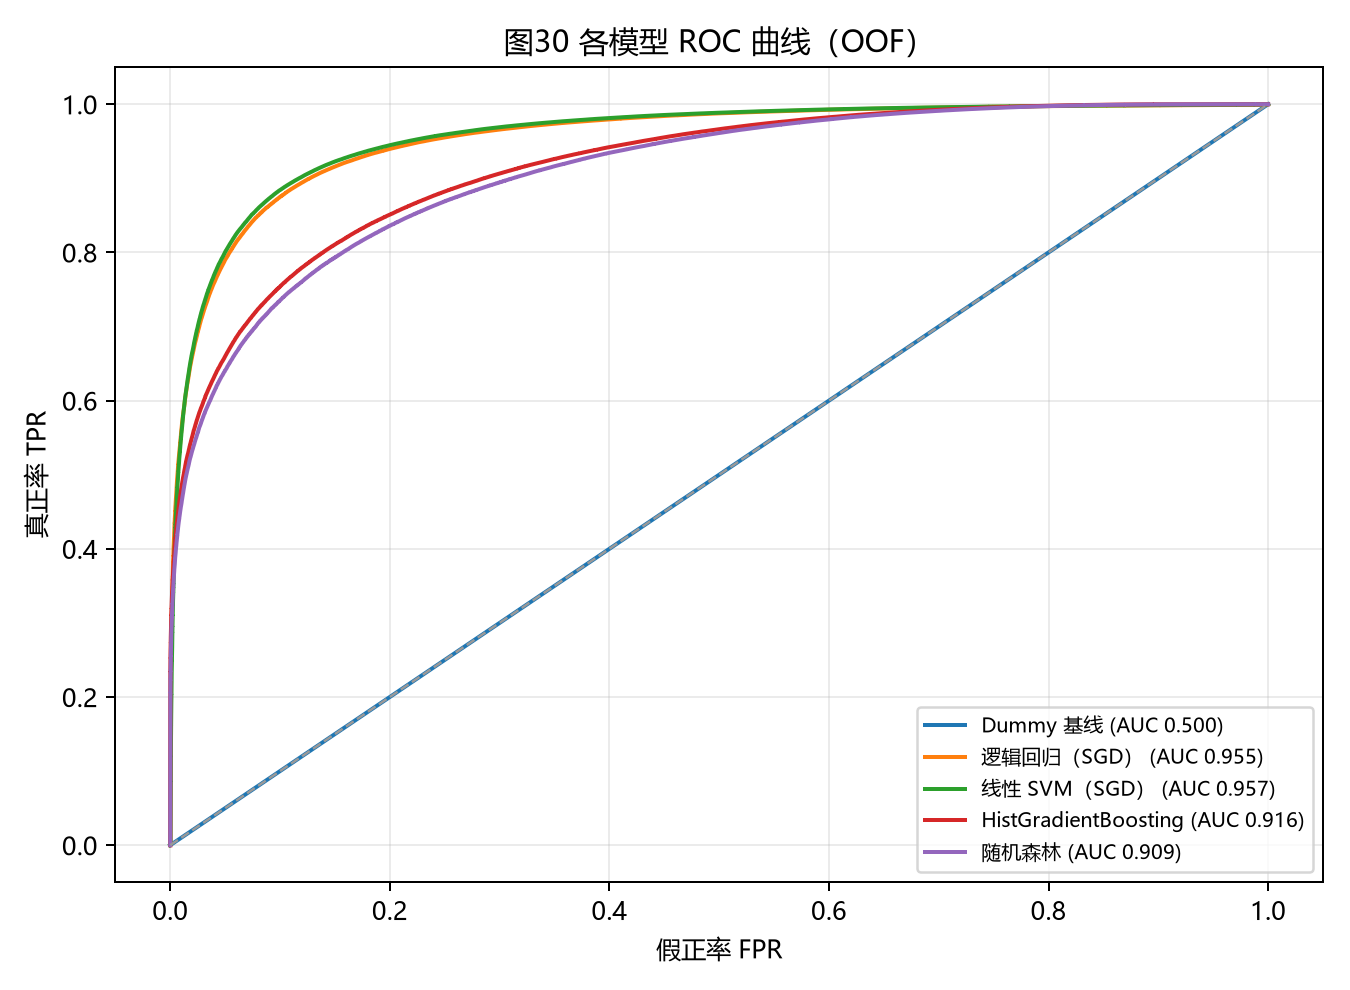

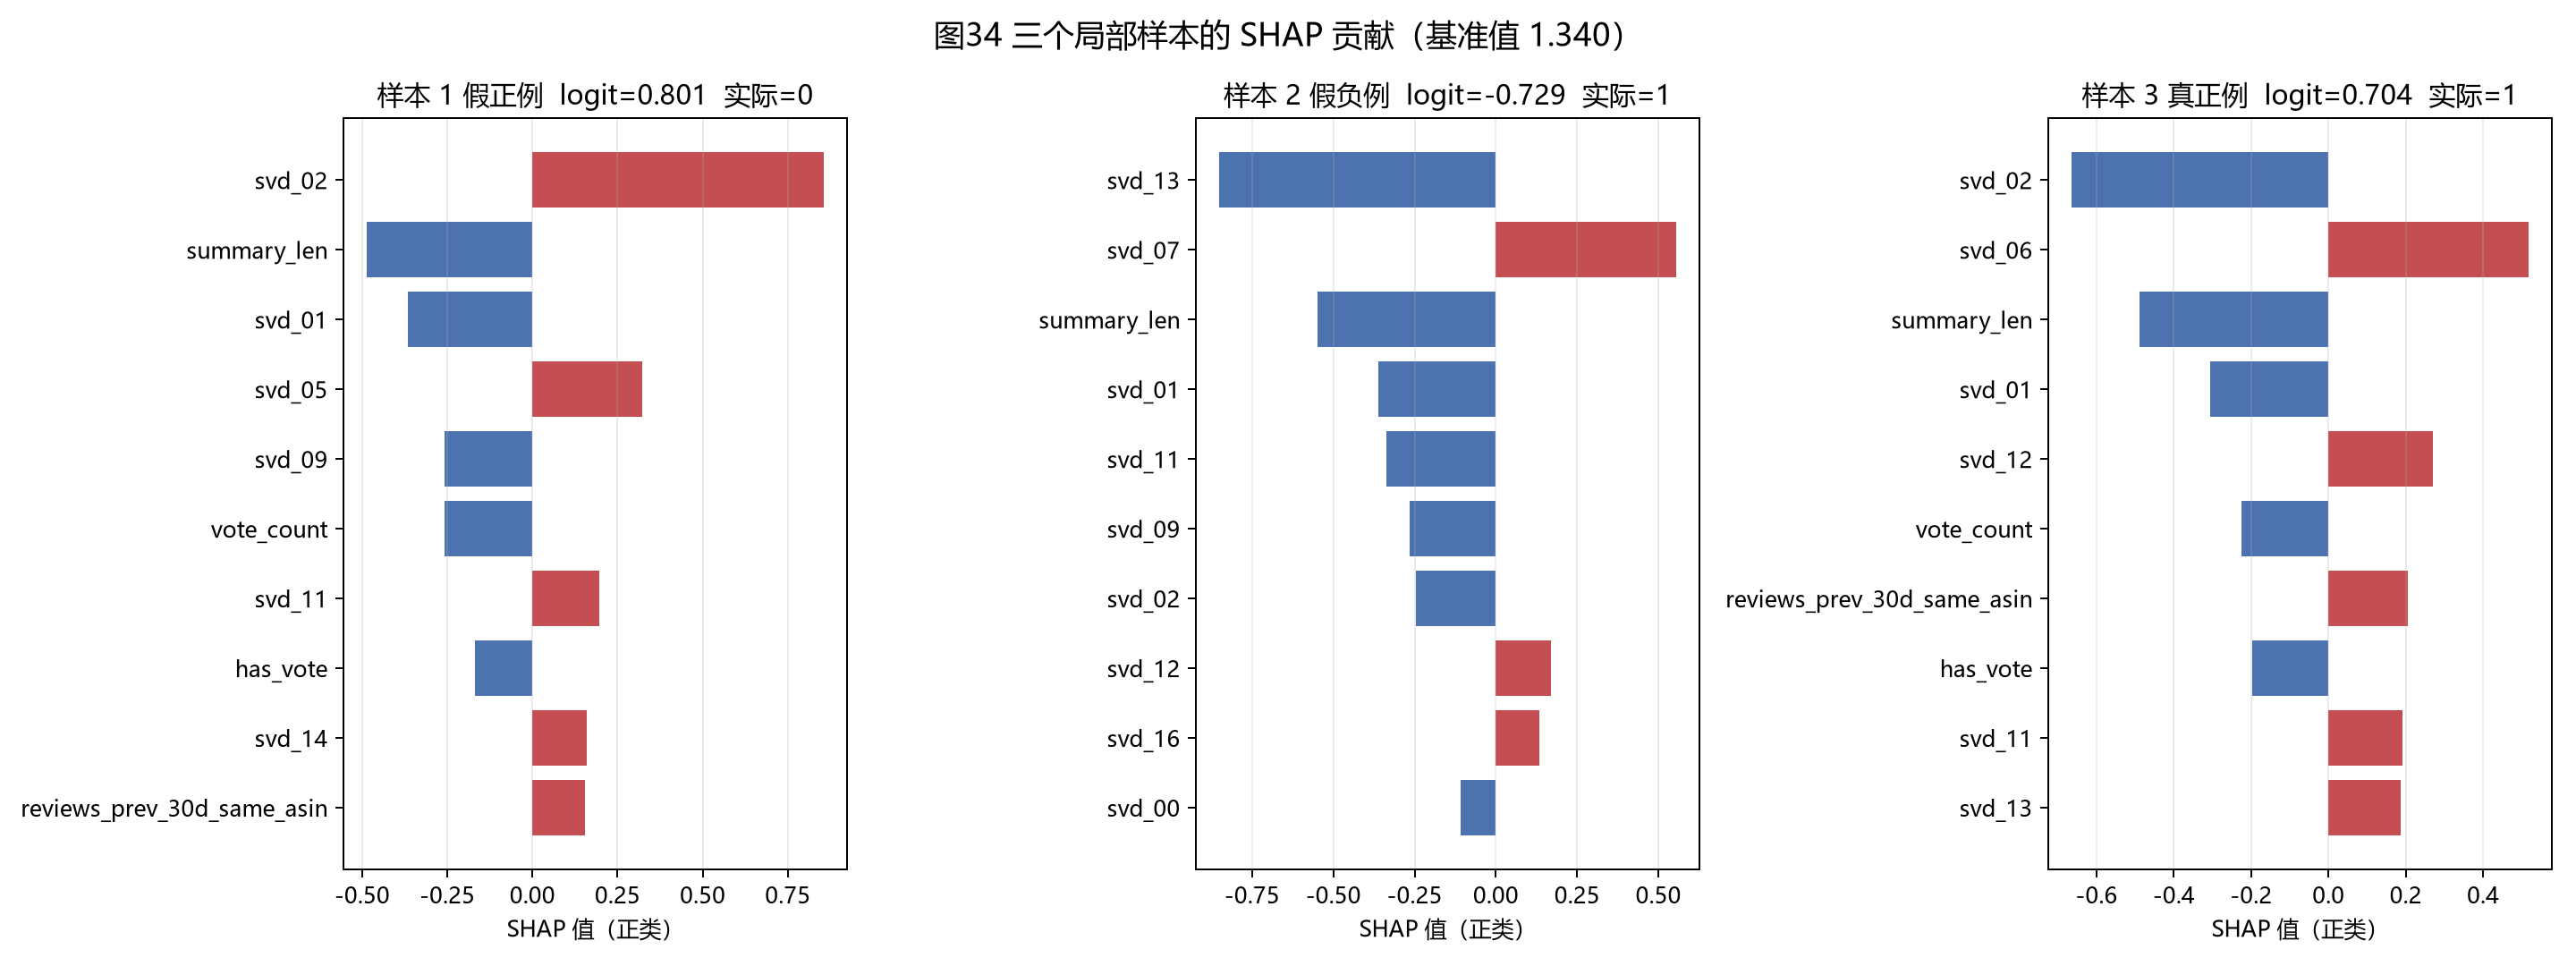

In [5]:
for name in ["fig30_classify_roc.png", "fig34_classify_shap.png"]:
    path = ROOT / "results" / "figures" / name
    if path.exists():
        display(Image(filename=str(path), width=760))
    else:
        print("缺少", path.name)


## 可选：全量重跑

默认不执行。把环境变量 `RUN_FULL_PIPELINE` 设为 `1` 后，本节会调用 `src/run_all.py` 重跑整条流水线，耗时约十几分钟。


In [6]:
if os.environ.get("RUN_FULL_PIPELINE") == "1":
    subprocess.run([sys.executable, str(ROOT / "src" / "run_all.py")], cwd=ROOT, check=True)
else:
    print("跳过全量重跑；需要时设置 RUN_FULL_PIPELINE=1")


跳过全量重跑；需要时设置 RUN_FULL_PIPELINE=1
